# Earth-to-Mars Planner

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from cesium.constants import AU_TO_M, DAY_TO_SEC, M_TO_KM
from cesium.guidance.mission_design import (
    EarthDepartureGrid,
    EarthLaunchWindow,
    InterplanetaryTrajectory,
    InterplanetaryTransferGrid,
)
from cesium.math.time import greg_to_jd, jd_to_greg
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.orbital.porkchop import plot_porkchop
from cesium.orbital.transformations import calc_dcm_eci_wrt_hci
from cesium.plotting import plot_3d
from cesium.world.constants import R_EARTH, R_SUN
from mission_io import export_fig, save_mission
from numpy.linalg import norm

## Time grid for intercept
From wikipedia, around 2035-2036 is optimal:

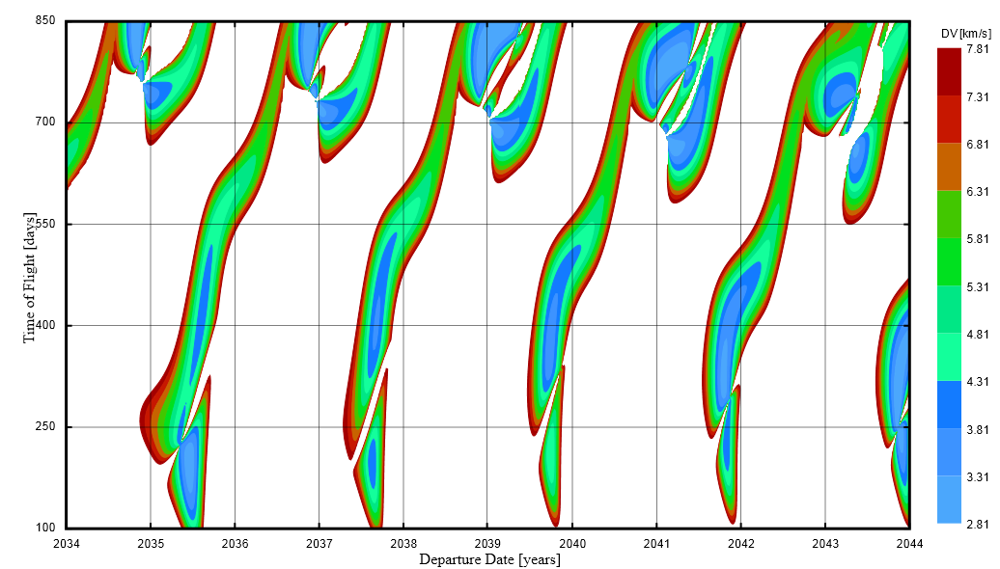

In [3]:
# start_jd = greg_to_jd(2043,6,0,0,0,0)
# end_jd = greg_to_jd(2044,6,0,0,0,0)
start_jd = greg_to_jd(2034, 6, 1, 0, 0, 0)
end_jd = greg_to_jd(2036, 1, 1, 0, 0, 0)
tof_bounds = (100, 550)

t_dep_jd = np.arange(start_jd, end_jd)
t_arr_jd = np.arange(start_jd + tof_bounds[0], end_jd + tof_bounds[1])
N_DEP = len(t_dep_jd)
N_ARR = len(t_arr_jd)
print(f"Search space length: ({N_DEP},{N_ARR})")


t_tot_jd = np.sort(np.concatenate((t_dep_jd, t_arr_jd)))

dep_grid_jd, arr_grid_jd = np.meshgrid(t_dep_jd, t_arr_jd, indexing="ij")
tof_grid_days = arr_grid_jd - dep_grid_jd

Search space length: (579,1029)


## Calculate characteristics

In [4]:
rv_dep_earth_hci = np.array(
    [np.ravel(planet_elements_and_rv(3, t)[1:]) for t in t_dep_jd]
)
rv_arr_mars_hci = np.array(
    [np.ravel(planet_elements_and_rv(4, t)[1:]) for t in t_arr_jd]
)

dcm_eci_wrt_hci = calc_dcm_eci_wrt_hci()

In [5]:
earth_to_mars = InterplanetaryTransferGrid(
    "Earth to Mars Transfer", start_jd, end_jd, tof_bounds, (3, 4), resolution_days=1
)
earth_to_mars.compute_grid()

'Earth to Mars Transfer' - Initialized with:
	Search space of: (579, 1029) with 1 days resolution
`Earth to Mars Transfer` - Computing grid:


100%|██████████| 579/579 [00:11<00:00, 52.29it/s]


In [6]:
earth_departure = EarthDepartureGrid(earth_to_mars)

## Plots

In [7]:
common_options = {
    "xlabel": "Earth departure Date",
    "ylabel": "Time-of-flight [day]",
    "xaxis": "gregorian",
    "yaxis": "time-of-flight",
    "xrange": (start_jd, end_jd),
    "yrange": tof_bounds,
    "show": True,
}

In [8]:
fig = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    earth_to_mars.C3_grid_km2,
    # zmin=0, zmax=100,
    contour_min=2.81**2,
    contour_max=7.81**2,
    contour_step=2,  # same bounds as nasa plot
    title="Earth-to-Mars departure C3",
    zlabel="C3 [km²/s²]",
    **common_options,
)

In [ ]:
export_fig(fig, "interplanetary", "porkchop_c3")

In [9]:
fig = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    earth_departure.dla_grid,
    contour_min=-40,
    contour_max=40,
    contour_step=2,
    title="Earth-to-Mars Declination",
    zlabel="Declination [º]",
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>DLA: %{z:.2f}º<extra></extra>",
    **common_options,
)

In [ ]:
export_fig(fig, "interplanetary", "porkchop_declination")

In [10]:
v_dep_hci_km_norm = norm(earth_to_mars.v_dep_pci_km, axis=2)
v_arr_hci_km_norm = norm(earth_to_mars.v_arr_pci_km, axis=2)

fig = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    v_arr_hci_km_norm,
    # zmin=0, zmax=100,
    contour_min=0,
    contour_max=10,
    contour_step=1,
    title="Earth-to-Mars Arrival Excess Speed",
    zlabel="V_arr_inf in HCI [km/s]",
    **common_options,
)

In [ ]:
export_fig(fig, "interplanetary", "porkchop_vinf_arrival")

## Constraints

In [11]:
ARRIVAL_JD = 2461633
C3_MAX_KM = 15.0  # km/s
DLA_MAX = 33.0  # deg
V_ARR_MAX_KM = 3.5  # km/s


C3_mask = earth_to_mars.C3_grid_km2.copy()
C3_mask[earth_to_mars.C3_grid_km2 > C3_MAX_KM] = np.nan
C3_mask[abs(earth_departure.dla_grid) >= DLA_MAX] = np.nan

In [12]:
options = common_options | {
    "show": False,
    "xrange": (greg_to_jd(2035, 5, 1, 0, 0, 0), greg_to_jd(2035, 8, 1, 0, 0, 0)),
    "yrange": (100, 250),
}

fig = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    C3_mask,
    zmin=0,
    zmax=C3_MAX_KM,
    contour_min=0,
    contour_max=C3_MAX_KM,
    contour_step=0.5,
    title="Earth-to-Mars departure C3 with constraints (overlaid with declination and right ascension)",
    zlabel="C3 [km²/s²]",
    **options,
)

declination = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    earth_departure.dla_grid,
    contour_min=-10,
    contour_max=40,
    contour_step=5,
    coloring="lines",
    colorscale=["red", "red"],
    trace_kwargs={"showscale": False},
    **options,
)

ascension = plot_porkchop(
    t_dep_jd,
    t_arr_jd,
    earth_departure.rla_grid,
    contour_min=0,
    contour_max=360,
    contour_step=5,
    coloring="lines",
    colorscale=["blue", "blue"],
    trace_kwargs={"showscale": False},
    **options,
)

fig.add_traces(declination.data)
fig.add_traces(ascension.data)
fig.show()

In [ ]:
export_fig(fig, "interplanetary", "porkchop_c3_constrained")

## Selecting trajectory

In [13]:
# Start with all computed solutions, then narrow the window.
window = EarthLaunchWindow(earth_departure).filter(
    c3=(None, 15),
    rla=(0, 360),
    dla=(-33, 33),
    departure_bounds_jd=(
        greg_to_jd(2035, 6, 3, 0, 0, 0),
        greg_to_jd(2035, 6, 23, 0, 0, 0),
    ),
    arrival_bounds_jd=(
        greg_to_jd(2035, 12, 15, 0, 0, 0),
        greg_to_jd(2036, 1, 4, 0, 0, 0),
    ),
)
C3_window = window.C3_grid_km2
window_dep_i, window_arr_i = window.indices
print(f"{len(window_dep_i)} feasible transfers")

441 feasible transfers


In [14]:
launch_window_plot_options = common_options | {
    "yaxis": "gregorian",
    "xrange": (window.departure_bounds_jd[0] - 2, window.departure_bounds_jd[1] + 2),
    "yrange": (window.arrival_bounds_jd[0] - 2, window.arrival_bounds_jd[1] + 2),
}

fig = plot_porkchop(
    window.transfer.t_dep_jd,
    window.transfer.t_arr_jd,
    window.C3_grid_km2,
    contour_min=0,
    contour_max=15,
    contour_step=0.5,
    zmin=0,
    zmax=15,
    title="Earth-to-Mars launch window",
    zlabel="C3 [km²/s²]",
    markers={
        "departure_jd": greg_to_jd(2035, 6, 13, 0, 0, 0),
        "arrival_jd": greg_to_jd(2035, 12, 25, 0, 0, 0),
        "name": "Selected transfer",
    },
    **launch_window_plot_options,
)

In [ ]:
export_fig(fig, "interplanetary", "launch_window")

## Finer optimization

In [15]:
new_tof_bounds = (
    window.arrival_bounds_jd[0] - window.departure_bounds_jd[1],  # Shortest
    window.arrival_bounds_jd[1] - window.departure_bounds_jd[0],  # Longest
)

finer_grid = InterplanetaryTransferGrid(
    "Finer Launch Window",
    greg_to_jd(2035, 6, 13, 12, 0, 0),
    greg_to_jd(2035, 6, 15, 12, 0, 0),
    tof_bounds=(193, 197),
    planet_nums=(3, 4),
    resolution_days=0.01,
)
finer_grid.compute_grid()

'Finer Launch Window' - Initialized with:
	Search space of: (200, 600) with 0.01 days resolution
`Finer Launch Window` - Computing grid:


100%|██████████| 200/200 [00:02<00:00, 76.09it/s]


## Modeling of my chosen trajectory
Decided to choose a trajectory on my birthday of June 13th, and on Christmas

In [16]:
# BIRTHDAY_JD = greg_to_jd(2035, 6, 13, 23, 25, 0)
BIRTHDAY_JD = greg_to_jd(2035, 6, 14, 12, 0, 0)
CHRISTMAS_JD = greg_to_jd(2035, 12, 25, 0, 0, 0)
finer_window = EarthLaunchWindow(finer_grid)

# See the available arrival times for launching on my birthday
arrival_start, arrival_end = finer_window.arrival_bounds_for_departure(BIRTHDAY_JD)
print("Arrival bounds for my birthday:")
print(f"{jd_to_greg(arrival_start)}")
print(f"{jd_to_greg(arrival_end)}")

dep_i, arr_i = finer_window.select(
    BIRTHDAY_JD,  # more specific birthday time
    CHRISTMAS_JD,
)

Arrival bounds for my birthday:
(2035, 12, 24, 11, 59, 59.99806880950946)
(2035, 12, 28, 11, 59, 59.99034404754657)


In [17]:
birthday_trajectory = InterplanetaryTrajectory(
    "Birthday Mission Trajectory", BIRTHDAY_JD, CHRISTMAS_JD, (3, 4), 0.1
)
birthday_trajectory.launch_that_babyy()

'Birthday Mission Trajectory' - Initialized trajectory with:
	Departure: 	2035/06/14	12:00:00
	Arrival: 	2035/12/25	00:00:00
	Resolution: 0.1 days
Position difference (m): 593.9688873438499


In [18]:
fig = plot_3d(
    [
        birthday_trajectory.r_sat_hci,
        birthday_trajectory.rv_dep_body_hci[:, 0:3],
        birthday_trajectory.rv_arr_body_hci[:, 0:3],
    ],
    birthday_trajectory.t_eval_jd,
    trace_colors=["purple", "royalblue", "orangered"],
    labels=["Satellite", "Earth", "Mars"],
    bodies={"name": "Sun", "radius": R_SUN * 5, "color": "goldenrod"},
    frames={
        "name": "Earth ECI",
        "location": birthday_trajectory.rv_dep_body_hci[0, :3],
        "dcm_body_wrt_hci": calc_dcm_eci_wrt_hci(),
        "length": 0.1 * AU_TO_M,
    },
    title="Birthday Mission",
    show=False,
    azim=80,
    elev=30,
    camera_distance=3,
    units="AU",
    scale=AU_TO_M,
)
fig.show()

In [ ]:
export_fig(fig, "interplanetary", "transfer_3d")

In [19]:
# Translate by Earth's position at each sample, then rotate HCI into ECI.
r_sat_eci = (
    birthday_trajectory.r_sat_hci - birthday_trajectory.rv_dep_body_hci[:, :3]
) @ calc_dcm_eci_wrt_hci().T
fig_earth = plot_3d(
    r_sat_eci,
    birthday_trajectory.t_eval_jd,
    labels="Satellite",
    trace_colors="purple",
    bodies={"name": "Earth", "radius": R_EARTH, "color": "royalblue"},
    frames={
        "name": "ECI",
        "location": [0, 0, 0],
        "dcm_body_wrt_hci": np.eye(3),
        "length": 10000 / M_TO_KM,
    },
    title="Earth departure — 50,000 km view",
    units="km",
    scale=1 / M_TO_KM,
    azim=80,
    elev=30,
    show_end=False,
    show=False,
)
fig_earth.update_scenes(
    xaxis_range=[-50000, 50000],
    yaxis_range=[-50000, 50000],
    zaxis_range=[-50000, 50000],
)
fig_earth.show()

In [ ]:
export_fig(fig_earth, "interplanetary", "departure_direction_eci")

## Save results!
- HCI Lambert departure [JD]
- HCI Lambert arrival [JD]
- tof [s]
- dt [s]
- Time grid [s since Lambert departure]
- Earth HCI rv [km, km/s]
- Mars HCI rv [km, km/s]
- Satellite HCI rv [km, km/s]

These are heliocentric reference epochs, NOT liftoff, injection-burn, or SOI-crossing times


In [20]:
trajectory = birthday_trajectory
mission_time_s = (trajectory.t_eval_jd - trajectory.departure_jd) * DAY_TO_SEC
satellite_rv_hci_km = (
    np.column_stack((trajectory.r_sat_hci, trajectory.v_sat_hci)) * M_TO_KM
)
assert satellite_rv_hci_km.shape == (len(mission_time_s), 6), (
    "Propagation did not reach every requested time"
)
assert np.isfinite(satellite_rv_hci_km).all(), "Non-finite spacecraft state"

MISSION_NAME = "birthday-christmas-earlier"
mission_path = save_mission(
    "interplanetary",
    MISSION_NAME,
    lambert_departure_jd=trajectory.departure_jd,
    lambert_arrival_jd=trajectory.arrival_jd,
    tof_s=trajectory.tof_s,
    time_s=mission_time_s,
    dt_s=np.diff(mission_time_s),
    earth_rv_hci_km=trajectory.rv_dep_body_hci * M_TO_KM,
    mars_rv_hci_km=trajectory.rv_arr_body_hci * M_TO_KM,
    satellite_rv_hci_km=satellite_rv_hci_km,
    frame="HCI",
    position_units="km",
    velocity_units="km/s",
    time_origin="lambert_departure",
    trajectory_model="heliocentric_two_body_lambert",
)
print(mission_path)

/Users/cskin/cesium/gnc/projects/mars-courier/trajectories/interplanetary-birthday_christmas_earlier.mission


## Thoughts

Next step would be modeling a range of dates to see what the best would be